# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

**Estudiante ID 14** · Semilla 1014 · Reto S12 (línea base) + Avance 2 (mejora propuesta para la semana 13).

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
# ============================================================
# 1. IMPORTACIONES
# ============================================================
# hashlib / json / Path: huella de la muestra, reporte JSON y rutas de archivo.
import hashlib
import json
from pathlib import Path

# numpy / pandas: manejo numérico y tablas de datos.
import numpy as np
import pandas as pd

# scikit-learn: partición de datos, preprocesamiento, modelos y métricas.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer          # aplica transformaciones distintas por tipo de columna
from sklearn.pipeline import make_pipeline             # encadena preprocesamiento + modelo
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer               # rellena valores faltantes
from sklearn.dummy import DummyClassifier              # modelo de referencia (clase mayoritaria)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
# ============================================================
# 2. CARGA DE DATOS (7 tablas de Olist)
# ============================================================
# Se leen desde una copia pública de GitHub con una revisión (commit) FIJA,
# de modo que todos los estudiantes y todas las semanas usan exactamente los mismos datos.
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')            # estado y fechas del pedido
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')         # precio, flete, producto y vendedor
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')        # peso, dimensiones, categoría
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')        # ciudad/estado del cliente
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')        # ciudad/estado del vendedor
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')      # medio de pago, cuotas, importe
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')  # traducción de categorías

# Verificación rápida de tamaños (filas, columnas) de cada tabla.
print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# ============================================================
# 3. PREPARACIÓN (I): RESUMEN DE ÍTEMS Y VENDEDORES POR PEDIDO
# ============================================================
# validate='many_to_one' garantiza que cada unión NO duplique filas por error.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

# Volumen del producto = largo x alto x ancho (cm3).
items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
# Categoría en inglés; si falta, la original; si tampoco existe, 'sin_categoria'.
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: UNA fila por pedido (un pedido puede tener varios ítems).
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),                  # suma de precios
    valor_flete=('freight_value', 'sum'),              # suma de fletes
    precio_maximo=('price', 'max'),                    # ítem más caro
    cantidad_items=('order_item_id', 'count'),         # número de ítems
    cantidad_productos=('product_id', 'nunique'),      # productos distintos
    cantidad_vendedores=('seller_id', 'nunique'),      # vendedores distintos
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del ítem de MAYOR precio (desempate por order_item_id).
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# ============================================================
# 4. PREPARACIÓN (II): PAGOS E INTEGRACIÓN DE TABLAS
# ============================================================
# Resumen de pagos por pedido (un pedido puede pagarse en varias filas).
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),   # cantidad de registros de pago
    cuotas_maximas=('payment_installments', 'max'), # máximo de cuotas
    valor_pagado=('payment_value', 'sum'),          # total pagado
)

# Medio de pago principal = el de mayor importe dentro del pedido.
pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración final: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

# Control de calidad: no deben existir pedidos duplicados tras las uniones.
assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# ============================================================
# 5. PREPARACIÓN (III): VARIABLES OBJETIVO Y DE CALENDARIO
# ============================================================
# Solo pedidos ENTREGADOS con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
# normalize() deja solo la fecha (sin hora): "tardío" se mide por DÍA, no por hora.
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days   # plazo que se prometió al cliente
data['dias_entrega'] = (real - compra).dt.days          # objetivo de la regresión (días reales)
data['is_late'] = (real > prevista).astype(int)         # OBJETIVO de clasificación: 1 = tardía
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek         # 0 = lunes ... 6 = domingo
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

# Cercanía geográfica cliente-vendedor (proxy de distancia logística).
data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
# Proporción del flete sobre el total (se evita dividir entre cero).
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

# Se descartan fechas incoherentes (plazos o entregas negativas).
data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
# Orden fijo por order_id => la muestra es reproducible.
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
# ============================================================
# 6. DEFINICIÓN DE PREDICTORES (28 variables: 24 numéricas + 4 categóricas)
# ============================================================
# IMPORTANTE (fuga de información): NO se incluyen dias_entrega ni la fecha real
# de entrega, porque solo se conocen DESPUÉS de que el pedido llega.
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000   # se necesitan al menos 35.000 pedidos para la muestra
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# ============================================================
# 7. MUESTRA INDIVIDUAL Y PARTICIONES (ID asignado = 14)
# ============================================================
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 14
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE            # semilla propia => 1014
identificador = f'{ID_ESTUDIANTE:02d}'    # '14' (se usa en el nombre del JSON)

# Muestra de 35.000 pedidos, estratificada para conservar la proporción de tardías.
muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

# 70 % entrenamiento (24.500) y 30 % temporal (10.500).
train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
# El 30 % temporal se divide en 15 % validación (5.250) y 15 % prueba (5.250).
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

# Matrices de predictores (X) y objetivo (y). El conjunto TEST NO se toca hasta la semana 16.
X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

# Huella (hash) de la muestra: permite al profesor verificar que la muestra es la correcta.
huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 14 | Semilla: 1014
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: cc67cfaa181c


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
# ============================================================
# 8. PREPROCESAMIENTO Y MODELO DE REFERENCIA (BASELINE)
# ============================================================
# Numéricas: mediana para faltantes + estandarización (media 0, desviación 1).
# Categóricas: categoría más frecuente para faltantes + One-Hot Encoding
# (handle_unknown='ignore' evita errores con categorías no vistas en entrenamiento).
# Todo se ajusta SOLO con entrenamiento (dentro del Pipeline) => sin fuga de información.
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

# Modelo de referencia: predice siempre la clase mayoritaria ("a tiempo").
# Sirve de "piso": cualquier modelo útil debe superarlo en métricas de la clase tardía.
referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))
# Recall de la referencia (guardado para compararlo en la interpretación).
recall_ref = recall_score(y_valid, pred_ref, zero_division=0)
print('Recall referencia:', round(recall_ref, 3))

Accuracy referencia: 0.932
F1 referencia: 0.0
Recall referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [9]:
# ============================================================
# ACTIVIDAD 1. ENTRENAMIENTO DE LA REGRESIÓN LOGÍSTICA
# ============================================================
# Decisión: class_weight='balanced'.
# Solo ~6,8 % de los pedidos son tardíos. Sin ponderar, el modelo apenas arriesga
# predecir "tardío" y su Recall es muy bajo. 'balanced' pondera cada clase de forma
# inversa a su frecuencia, penalizando más equivocarse con la clase minoritaria
# (justo la que cuesta R$35 por falso negativo vs R$8 por falso positivo).
peso_clases = 'balanced'   # alternativa evaluada más abajo: None

modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=peso_clases,  # ponderación de clases
                       max_iter=1000,             # tope de iteraciones (evita no convergencia)
                       random_state=semilla)      # reproducibilidad
)
modelo.fit(X_train, y_train)      # ajusta preprocesamiento + modelo con ENTRENAMIENTO
pred = modelo.predict(X_valid)    # predicciones (0/1) sobre VALIDACIÓN, umbral 0,5

print('Modelo entrenado.')
print('Predicciones de validación:', len(pred))

# --- Comparación auxiliar para justificar class_weight (no altera `modelo` ni `pred`) ---
from sklearn.base import clone
modelo_sin_peso = make_pipeline(
    clone(preprocesamiento),                                          # copia independiente del preprocesamiento
    LogisticRegression(class_weight=None, max_iter=1000, random_state=semilla)
)
modelo_sin_peso.fit(X_train, y_train)
pred_sin_peso = modelo_sin_peso.predict(X_valid)
comparacion_pesos = pd.DataFrame({
    'class_weight': [None, 'balanced'],
    'accuracy': [accuracy_score(y_valid, pred_sin_peso), accuracy_score(y_valid, pred)],
    'recall':   [recall_score(y_valid, pred_sin_peso, zero_division=0), recall_score(y_valid, pred)],
    'precision':[precision_score(y_valid, pred_sin_peso, zero_division=0), precision_score(y_valid, pred)],
    'f1':       [f1_score(y_valid, pred_sin_peso, zero_division=0), f1_score(y_valid, pred)],
})
display(comparacion_pesos.round(4))

/tmp/claude-0/-home-claude/7cf60df0-e03c-566f-8853-6efafd77d058/scratchpad/build/v/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Modelo entrenado.
Predicciones de validación: 5250


/tmp/claude-0/-home-claude/7cf60df0-e03c-566f-8853-6efafd77d058/scratchpad/build/v/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,class_weight,accuracy,recall,precision,f1
0,None,0.9324,0.0000,0.0000,0.0000
1,balanced,0.6790,0.6366,0.1268,0.2115


## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [10]:
# ============================================================
# ACTIVIDAD 2. MÉTRICAS EN VALIDACIÓN
# ============================================================
# Probabilidad de ser tardío (columna 1 de predict_proba). Las métricas AUC la requieren
# porque evalúan el ORDEN de las probabilidades, no solo la clase final.
proba = modelo.predict_proba(X_valid)[:, 1]

medidas = {
    'accuracy': float(accuracy_score(y_valid, pred)),                       # aciertos globales
    'precision': float(precision_score(y_valid, pred, zero_division=0)),    # de los alertados, cuántos eran tardíos
    'recall': float(recall_score(y_valid, pred, zero_division=0)),          # de los tardíos, cuántos se detectaron
    'f1': float(f1_score(y_valid, pred, zero_division=0)),                  # equilibrio precision/recall
    'roc_auc': float(roc_auc_score(y_valid, proba)),                        # capacidad de ordenar tardíos > a tiempo
    'ap': float(average_precision_score(y_valid, proba)),                   # área precision-recall (útil con clase rara)
}

# Matriz de confusión: filas = real, columnas = predicho -> [[TN, FP], [FN, TP]]
matriz = confusion_matrix(y_valid, pred, labels=[0, 1])
print('Matriz de confusión [ [TN, FP], [FN, TP] ]:')
print(matriz)
print('Métricas:')
display(pd.DataFrame([medidas]).round(4))

Matriz de confusión [ [TN, FP], [FN, TP] ]:
[[3339 1556]
 [ 129  226]]
Métricas:


,accuracy,precision,recall,f1,roc_auc,ap
0,0.679,0.1268,0.6366,0.2115,0.7036,0.1605


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [11]:
# ============================================================
# ACTIVIDAD 3. ERRORES POR SEGMENTO (MES Y ESTADO DEL CLIENTE)
# ============================================================
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
# error = 1 cuando la predicción no coincide con la realidad (FP o FN).
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# Por mes de compra: cantidad de pedidos, errores y tasa de error (%).
errores_mes = analisis.groupby('mes_compra', as_index=False).agg(
    pedidos=('order_id', 'count'),
    errores=('error', 'sum'),
    tasa_error=('error', 'mean')
).sort_values('mes_compra')

# Por estado del cliente, ordenado de mayor a menor tasa de error.
# Se muestra 'pedidos' porque una tasa alta con pocos pedidos NO es concluyente.
errores_estado = analisis.groupby('customer_state', as_index=False).agg(
    pedidos=('order_id', 'count'),
    errores=('error', 'sum'),
    tasa_error=('error', 'mean')
).sort_values(['tasa_error', 'pedidos'], ascending=[False, False])

print('Error por mes de compra:')
display(errores_mes.round(4))
print('Error por estado del cliente (ordenado por tasa de error):')
display(errores_estado.round(4))

# Segmentos con volumen relevante (>= 100 pedidos) para una lectura más confiable.
print('Estados con al menos 100 pedidos en validación:')
display(errores_estado[errores_estado['pedidos'] >= 100].round(4))

Error por mes de compra:


,mes_compra,pedidos,errores,tasa_error
0,1,415,152,0.3663
1,2,422,155,0.3673
2,3,525,204,0.3886
3,4,475,136,0.2863
4,5,558,193,0.3459
5,6,546,121,0.2216
6,7,546,205,0.3755
7,8,561,231,0.4118
8,9,224,62,0.2768
9,10,272,78,0.2868


Error por estado del cliente (ordenado por tasa de error):


,customer_state,pedidos,errores,tasa_error
13,PA,44,35,0.7955
9,MA,41,32,0.7805
4,BA,181,139,0.7680
1,AL,36,25,0.6944
5,CE,73,50,0.6849
18,RJ,673,451,0.6701
24,SE,18,12,0.6667
14,PB,31,20,0.6452
23,SC,207,131,0.6329
19,RN,21,12,0.5714


Estados con al menos 100 pedidos en validación:


,customer_state,pedidos,errores,tasa_error
4,BA,181,139,0.7680
18,RJ,673,451,0.6701
23,SC,207,131,0.6329
7,ES,119,61,0.5126
6,DF,101,41,0.4059
22,RS,293,67,0.2287
10,MG,664,111,0.1672
25,SP,2132,324,0.1520
17,PR,270,34,0.1259


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [12]:
# ============================================================
# ACTIVIDAD 4. COSTO EMPRESARIAL DE LOS ERRORES
# ============================================================
# Supuesto didáctico: falso positivo (FP) = R$ 8, falso negativo (FN) = R$ 35.
# FP: se interviene un pedido que iba a llegar a tiempo (costo operativo innecesario).
# FN: no se detecta un pedido tardío (cliente insatisfecho, más costoso).
COSTO_FP, COSTO_FN = 8, 35
tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
costo_fp_fn = int(COSTO_FP * fp + COSTO_FN * fn)   # costo total = 8*FP + 35*FN

print(f'Falsos positivos (FP): {fp} | Costo: R${COSTO_FP * fp:,.0f}')
print(f'Falsos negativos (FN): {fn} | Costo: R${COSTO_FN * fn:,.0f}')
print(f'Costo total de errores: R${costo_fp_fn:,.0f}')

# Referencia: costo del modelo "siempre a tiempo" (todos los tardíos son FN).
costo_referencia = int(COSTO_FN * (y_valid == 1).sum())
print(f'Costo del modelo de referencia (siempre a tiempo): R${costo_referencia:,.0f}')

Falsos positivos (FP): 1556 | Costo: R$12,448
Falsos negativos (FN): 129 | Costo: R$4,515
Costo total de errores: R$16,963
Costo del modelo de referencia (siempre a tiempo): R$12,425


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [13]:
# ---- Autoverificación: comprueba tamaños, particiones sin traslape, predicciones, métricas y costo ----
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [14]:
# ============================================================
# 9. EJEMPLO GUIADO DE REGRESIÓN: DÍAS DE ENTREGA (Ridge)
# ============================================================
from sklearn.base import clone

# clone(): cada modelo recibe una copia independiente (sin estado) del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])        # objetivo continuo: días reales de entrega
pred_dias = modelo_reg.predict(X_valid)
# MAE: error absoluto medio, en días (qué tanto se equivoca en promedio).
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.21 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

**Respuesta:**

| Modelo (validación, 5.250 pedidos) | Accuracy | Recall | F1 |
|---|---|---|---|
| Referencia (siempre "a tiempo") | 0,932 | 0,000 | 0,000 |
| Regresión logística, `class_weight='balanced'` | 0,679 | 0,637 | 0,212 |

La referencia tiene la Accuracy más alta (0,932) únicamente porque ~93 % de los pedidos llega a tiempo; no detecta ni una sola entrega tardía (Recall = 0). La regresión logística pierde ~25 puntos de Accuracy, pero detecta 226 de las 355 entregas tardías (Recall 0,637) y su F1 pasa de 0 a 0,212. Su Precision es baja (0,127): de cada 100 alertas, solo ~13 son realmente tardías, porque la clase positiva es rara (6,8 %). El ROC-AUC de 0,704 indica una capacidad moderada de ordenar los pedidos por riesgo, y el AP de 0,161 es ~2,4 veces la prevalencia (0,068): hay señal, pero limitada.

**Elección de `class_weight`:** se eligió `'balanced'`. En la comparación de la Actividad 1, con `class_weight=None` el modelo termina prediciendo "a tiempo" para casi todo (Accuracy 0,932, Recall 0, F1 0), equivalente a la referencia y sin utilidad operativa. `'balanced'` penaliza más los errores sobre la clase minoritaria, que es justo la costosa (R$35 por falso negativo frente a R$8 por falso positivo), y permite detectar el 63,7 % de los retrasos.


2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

**Respuesta:**

*Por mes de compra:* el error es mayor en agosto (41,2 %, 561 pedidos), marzo (38,9 %, 525) y julio (37,6 %, 546), y menor en diciembre (13,3 %, 300) y junio (22,2 %, 546). Son segmentos con cientos de pedidos, por lo que la diferencia es razonablemente confiable.

*Por estado del cliente:* las tasas más altas aparecen en PA (79,5 %) y MA (78,1 %), pero con solo 44 y 41 pedidos, por lo que son poco concluyentes. Entre los estados con al menos 100 pedidos, los de mayor error son BA (76,8 %, 181 pedidos), RJ (67,0 %, 673), SC (63,3 %, 207) y ES (51,3 %, 119); los de menor error son PR (12,6 %, 270), SP (15,2 %, el estado más grande con 2.132 pedidos) y MG (16,7 %, 664).

*Contexto (Avance 2, sección 8):* los estados con más error también son los de más retrasos reales: ES (16,8 %), BA (11,6 %), RJ (11,1 %) y SC (11,1 %), frente a SP (4,2 %), MG (4,1 %) y PR (2,6 %), con un promedio de la muestra de 6,8 %. Aun así, como incluso en esos estados la gran mayoría de los pedidos llega a tiempo, el modelo "balanced" alerta en exceso y casi todo su error son falsos positivos.

*Relación con los costos:* de los 1.685 errores totales, 1.556 son falsos positivos y solo 129 son falsos negativos. Cada falso positivo cuesta R$8 (R$12.448 en total) y cada falso negativo R$35 (R$4.515), para un costo total de R$16.963. Aunque el falso negativo es 4,4 veces más caro por unidad, el volumen de falsos positivos domina el costo. Un hallazgo importante: el modelo de referencia (que nunca alerta) tendría 355 falsos negativos y un costo de R$12.425, **menor** que el de la regresión logística con umbral 0,5. Con estos costos supuestos, el modelo solo se justifica si se ajusta el umbral de decisión (ver Avance 2). Limitación: los costos de R$8 y R$35 son supuestos didácticos, no costos verificados de Olist.


3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

**Respuesta:**

**Propuesta:** (a) reemplazar la regresión logística por un modelo no lineal (Random Forest), que puede capturar interacciones como estado del cliente × estado del vendedor × plazo prometido, y (b) elegir el umbral de decisión minimizando el costo `8*FP + 35*FN` en lugar de usar 0,5 por defecto. Para la semana 13 queda además pendiente probar variables nuevas (por ejemplo, un indicador de ruta estado-vendedor → estado-cliente) y otro tratamiento de las categóricas con muchas categorías (`categoria_principal`).

**Verificación (ya ejecutada en la sección 8, con la misma muestra y las mismas particiones, entrenando solo con `train` y comparando en `valid`):**

| Modelo | Recall | Precision | ROC-AUC | AP | Costo (R$) |
|---|---|---|---|---|---|
| Referencia (nunca alerta) | 0,000 | – | – | – | 12.425 |
| Reg. logística, umbral 0,5 | 0,637 | 0,127 | 0,704 | 0,161 | 16.963 |
| Reg. logística, umbral óptimo (0,73) | 0,245 | 0,214 | 0,704 | 0,161 | 11.932 |
| Random Forest, umbral 0,5 | 0,397 | 0,241 | 0,755 | 0,224 | 11.042 |
| Random Forest, umbral óptimo (0,53) | 0,318 | 0,268 | 0,755 | 0,224 | 10.934 |

El Random Forest mejora el ordenamiento del riesgo (ROC-AUC 0,704 → 0,755; AP 0,161 → 0,224) y reduce el costo en validación de R$16.963 a R$10.934 (-35,5 %), quedando también por debajo del modelo de referencia (R$12.425). La mejora se considera real porque mejora varias métricas a la vez (no solo Accuracy) y el costo.

**Limitaciones:** el umbral óptimo se eligió sobre la misma validación, por lo que el ahorro es optimista; las diferencias deben confirmarse con la incertidumbre de la semana 14 (intervalos o remuestreo) y, al final, con la partición de prueba de la semana 16. Además, los costos de R$8 y R$35 son supuestos didácticos, y con un umbral alto el Recall cae (0,318), de modo que la mayoría de los retrasos seguiría sin detectarse.


## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [15]:
# ============================================================
# 10. REGISTRO DE RESULTADOS (JSON del reto S12)
# ============================================================
# Guarda ID, semilla, versiones, huella de la muestra, métricas y costo para que el
# profesor pueda reproducir y verificar la entrega. Archivo: reports/S12_resultados_ID_14.json
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_14.json
Si no se descargó automáticamente, guarde manualmente: reports/S12_resultados_ID_14.json


## 8. Avance 2: mejora propuesta para la semana 13

Se prueba la mejora propuesta en la pregunta 3, **siempre con la misma muestra y las mismas particiones** (entrenar con `train`, comparar en `valid`; `test` no se usa). Se evalúan dos ideas:

1. **Modelo no lineal:** Random Forest, que puede capturar relaciones no lineales e interacciones (por ejemplo, entre estado del cliente, estado del vendedor y plazo prometido) que la regresión logística no ve.
2. **Umbral de decisión según el costo:** en lugar del umbral fijo de 0,5, elegir el umbral que minimiza el costo `8*FP + 35*FN`.

Nota: elegir el umbral sobre la validación es optimista (se ajusta a esos mismos datos); la confirmación honesta se hace en la partición de prueba en la semana 16.

In [16]:
# ============================================================
# AVANCE 2 (a). RANDOM FOREST CON EL MISMO PREPROCESAMIENTO Y PARTICIONES
# ============================================================
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

modelo_rf = make_pipeline(
    clone(preprocesamiento),                    # misma transformación de variables que el modelo base
    RandomForestClassifier(
        n_estimators=300,                       # número de árboles
        min_samples_leaf=20,                    # hojas grandes => probabilidades más suaves y menos sobreajuste
        class_weight='balanced_subsample',      # compensa el desbalance en cada árbol
        n_jobs=-1,                              # usa todos los núcleos disponibles
        random_state=semilla)                   # reproducible
)
modelo_rf.fit(X_train, y_train)                 # solo ENTRENAMIENTO
proba_rf = modelo_rf.predict_proba(X_valid)[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)         # umbral estándar de 0,5

def resumen_modelo(nombre, y_real, proba_m, pred_m):
    """Devuelve una fila con las métricas y el costo (8*FP + 35*FN) de un modelo."""
    _, fp_, fn_, _ = confusion_matrix(y_real, pred_m, labels=[0, 1]).ravel()
    return {'modelo': nombre,
            'accuracy': accuracy_score(y_real, pred_m),
            'precision': precision_score(y_real, pred_m, zero_division=0),
            'recall': recall_score(y_real, pred_m, zero_division=0),
            'f1': f1_score(y_real, pred_m, zero_division=0),
            'roc_auc': roc_auc_score(y_real, proba_m),
            'ap': average_precision_score(y_real, proba_m),
            'costo_brl': 8 * fp_ + 35 * fn_}

tabla_a2 = pd.DataFrame([
    resumen_modelo('Regresión logística (umbral 0,5)', y_valid, proba, pred),
    resumen_modelo('Random Forest (umbral 0,5)', y_valid, proba_rf, pred_rf),
])
display(tabla_a2.round(4))

,modelo,accuracy,precision,recall,f1,roc_auc,ap,costo_brl
0,"Regresión logística (umbral 0,5)",0.6790,0.1268,0.6366,0.2115,0.7036,0.1605,16963
1,"Random Forest (umbral 0,5)",0.8747,0.2410,0.3972,0.3000,0.7554,0.2236,11042


,modelo,umbral,recall,precision,fp,fn,costo_brl
0,Referencia (nunca alerta),NaN,0.0000,NaN,0.0,355.0,12425.0
1,"Reg. logística, umbral 0,5",0.50,0.6366,0.1268,1556.0,129.0,16963.0
2,"Reg. logística, umbral óptimo",0.73,0.2451,0.2143,319.0,268.0,11932.0
3,"Random Forest, umbral 0,5",0.50,0.3972,0.2410,444.0,214.0,11042.0
4,"Random Forest, umbral óptimo",0.53,0.3183,0.2684,308.0,242.0,10934.0


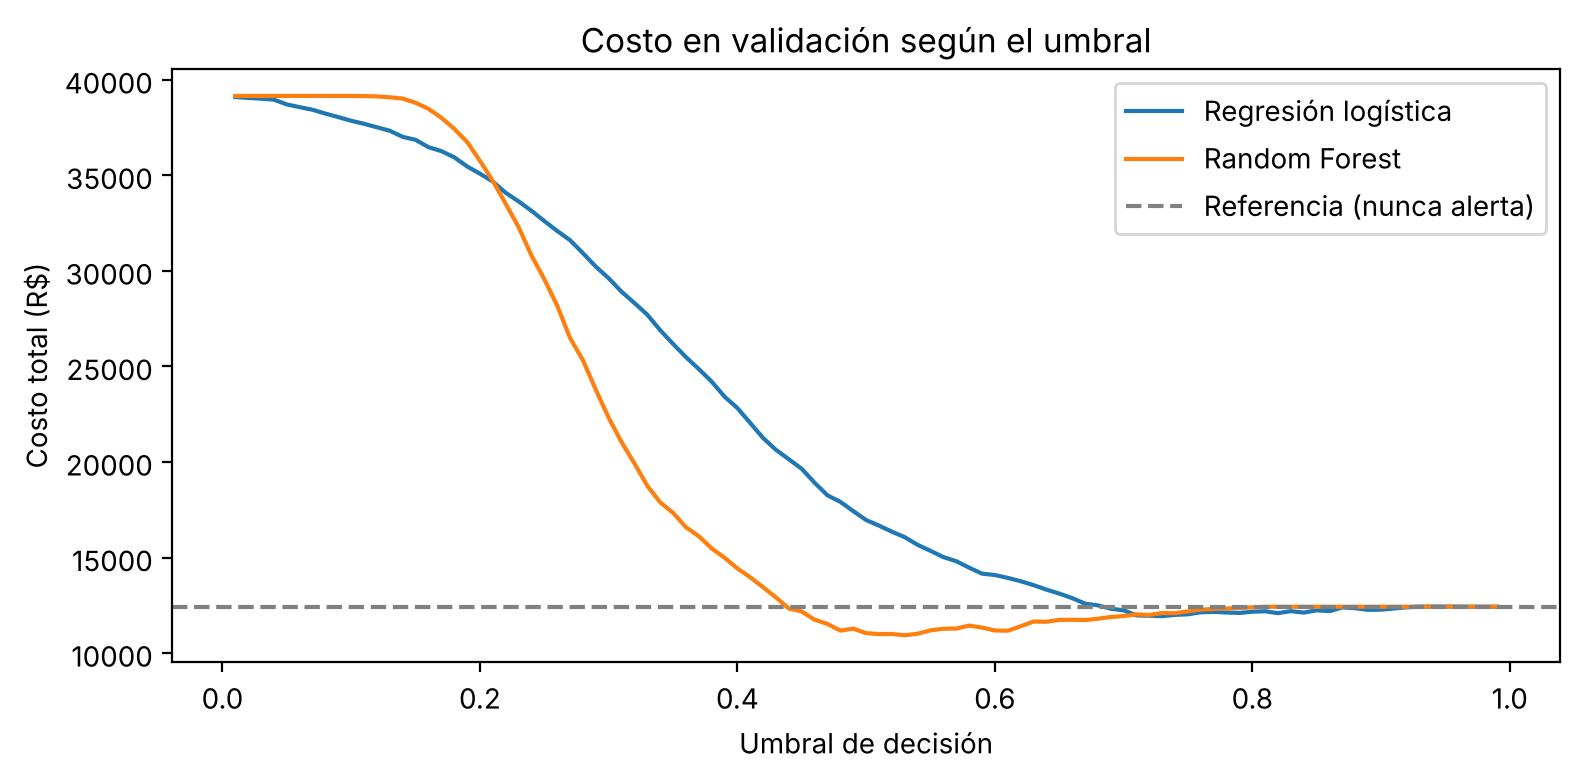

In [17]:
# ============================================================
# AVANCE 2 (b). UMBRAL ÓPTIMO SEGÚN COSTO (barrido sobre VALIDACIÓN)
# ============================================================
umbrales = np.linspace(0.01, 0.99, 99)

def barrido_costos(y_real, proba_m):
    """Para cada umbral calcula FP, FN, Recall, Precision y costo total."""
    filas = []
    for u in umbrales:
        p = (proba_m >= u).astype(int)
        _, fp_, fn_, tp_ = confusion_matrix(y_real, p, labels=[0, 1]).ravel()
        filas.append({'umbral': u, 'fp': fp_, 'fn': fn_,
                      'recall': tp_ / (tp_ + fn_),
                      'precision': tp_ / (tp_ + fp_) if (tp_ + fp_) else np.nan,
                      'costo_brl': 8 * fp_ + 35 * fn_})
    return pd.DataFrame(filas)

barrido_lr = barrido_costos(y_valid, proba)
barrido_rf = barrido_costos(y_valid, proba_rf)

# Fila de menor costo en cada modelo.
mejor_lr = barrido_lr.loc[barrido_lr['costo_brl'].idxmin()]
mejor_rf = barrido_rf.loc[barrido_rf['costo_brl'].idxmin()]
costo_ref = 35 * int((y_valid == 1).sum())   # modelo que nunca alerta: todos los tardíos son FN

resultado_umbral = pd.DataFrame([
    {'modelo': 'Referencia (nunca alerta)', 'umbral': np.nan, 'recall': 0.0, 'precision': np.nan, 'fp': 0,
     'fn': int((y_valid == 1).sum()), 'costo_brl': costo_ref},
    {'modelo': 'Reg. logística, umbral 0,5', **barrido_lr.loc[barrido_lr['umbral'].sub(0.5).abs().idxmin()].to_dict()},
    {'modelo': 'Reg. logística, umbral óptimo', **mejor_lr.to_dict()},
    {'modelo': 'Random Forest, umbral 0,5', **barrido_rf.loc[barrido_rf['umbral'].sub(0.5).abs().idxmin()].to_dict()},
    {'modelo': 'Random Forest, umbral óptimo', **mejor_rf.to_dict()},
])
display(resultado_umbral.round(4))

# Gráfico: costo total vs umbral.
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(barrido_lr['umbral'], barrido_lr['costo_brl'], label='Regresión logística')
plt.plot(barrido_rf['umbral'], barrido_rf['costo_brl'], label='Random Forest')
plt.axhline(costo_ref, color='gray', linestyle='--', label='Referencia (nunca alerta)')
plt.xlabel('Umbral de decisión'); plt.ylabel('Costo total (R$)')
plt.title('Costo en validación según el umbral'); plt.legend(); plt.tight_layout(); plt.show()

In [18]:
# ============================================================
# AVANCE 2 (c). ¿DÓNDE SE CONCENTRAN LOS RETRASOS? (contexto para los errores por segmento)
# ============================================================
# Tasa real de entregas tardías por estado (estados con >= 100 pedidos en validación):
tasa_real = (valid.groupby('customer_state')
             .agg(pedidos=('order_id', 'count'), tasa_tardias=('is_late', 'mean'))
             .query('pedidos >= 100').sort_values('tasa_tardias', ascending=False))
display(tasa_real.round(4))

,pedidos,tasa_tardias
customer_state,,
ES,119,0.1681
BA,181,0.1160
RJ,673,0.1114
SC,207,0.1111
RS,293,0.0887
DF,101,0.0594
SP,2132,0.0422
MG,664,0.0407
PR,270,0.0259
